# Event and Volume Clocks

Market activity is irregular. Sampling the local order book every 100 milliseconds can
repeat an unchanged observation during a quiet period and summarize many updates during
a busy one. An event clock instead waits for a fixed number of feed observations; a
volume clock waits for a traded-quantity threshold. Their elapsed sampling intervals vary.

This example compares all three clocks on the same BTCUSDT replay using
`wait_next_feed`. It collects mid-price, spread and top-of-book imbalance without placing
orders. The purpose is to demonstrate observation timing, not to establish that one clock
produces better forecasts.

## What counts as an event?

`wait_next_feed(False, timeout)` returns `2` for a market feed, `0` for a timeout and `1`
for end-of-data. Other results indicate errors (order responses are disabled here).
In the current backtester, records with the same local timestamp are processed together
before the call returns. We count one **feed batch** per successful feed wakeup, not one
trade, price-level update, exchange message or BBO change. A batch can contain depth
updates and/or trades. Counting batches is specific to the selected normalized feed.

The volume clock accumulates **market trade quantity**, not changes in displayed depth
or fills of our own orders. It emits one observation at the end of the batch that reaches
the threshold, includes the entire batch, then resets its accumulator. Actual interval
volume can therefore exceed the threshold. These are volume-threshold observations,
not exact equal-volume bars; we do not invent intermediate order books within a batch.

See [Working with Market Depth and Trades](https://hftbacktest.readthedocs.io/en/latest/tutorials/Working%20with%20Market%20Depth%20and%20Trades.html)
for book and trade-buffer access, and [Fusing Depth Data](https://hftbacktest.readthedocs.io/en/latest/tutorials/Fusing%20Depth%20Data.html)
for the effect of choosing different feed streams.

## Prepare the bundled sample

Run this notebook from the repository's `examples` directory with HftBacktest installed.
The two raw files below are included in the repository; no download or credentials are
required. Follow [Data Preparation](https://hftbacktest.readthedocs.io/en/latest/tutorials/Data%20Preparation.html) to learn about conversion
and initial snapshots. These files cover only a few minutes on either side of midnight,
not complete days. We use the August 8 final book to initialize August 9.

The standard converter processes depth and trades with its default `opt=''`; it does
not fuse the raw bookTicker stream. It corrects negative feed latency and event order,
so all three clocks use the same **normalized local timestamps**. The resulting sample
should not be used as evidence of calibrated live latency. A one-million-row conversion
buffer is sufficient for each bundled file (about 64 MB before sorting/output arrays).

In [1]:
from pathlib import Path

import numpy as np
import polars as pl
from matplotlib import pyplot as plt
from numba import njit

from hftbacktest import (
    BacktestAsset, HashMapMarketDepthBacktest,
    LOCAL_EVENT, TRADE_EVENT,
)
from hftbacktest.data.utils import binancefutures
from hftbacktest.data.utils.snapshot import create_last_snapshot

tick_size = 0.1
lot_size = 0.001
data_dir = Path('usdm')

for day in ('20240808', '20240809'):
    _ = binancefutures.convert(
        str(data_dir / f'btcusdt_{day}.gz'),
        output_filename=str(data_dir / f'btcusdt_{day}.npz'),
        buffer_size=1_000_000,
    )

snapshot = create_last_snapshot(
    [str(data_dir / 'btcusdt_20240808.npz')], tick_size, lot_size
)
with np.load(data_dir / 'btcusdt_20240809.npz') as archive:
    data = archive['data']

Correcting the latency


local_timestamp is ahead of exch_timestamp by 1272156851
Correcting the event order


Saving to usdm\btcusdt_20240808.npz


Correcting the latency
local_timestamp is ahead of exch_timestamp by 1273873720
Correcting the event order
Saving to usdm\btcusdt_20240809.npz


## Replay all three clocks together

The timeout is the time remaining until the next fixed-grid observation. A feed arriving
earlier advances the event and volume clocks; a timeout advances only the time clock.
Consequently the fixed grid is anchored at `start`, not restarted after each feed.
If a batch arrives exactly at a grid boundary, all three clocks see the book **after**
that batch. This is the same boundary convention as `elapse`.

Each row contains the observation time, features, and feed-batch count and traded BTC
since that clock's previous observation (or `start`). Top-of-book imbalance is
`(bid_qty - ask_qty) / (bid_qty + ask_qty)`; it is not full-depth or order-flow imbalance.
Absent, crossed or locked quotes, or nonpositive BBO quantities, produce NaN features.
We retain those rows so invalid books do not silently change the clock definition.

The compiled loop uses typed NumPy arrays. Epoch timestamps stay as signed 64-bit
integers, separate from floating-point prices. `last_trades_capacity` enables the trade
buffer; consume its values before clearing it, and never retain the view across replay
advances. The buffer is cleared even when no clock emits an observation.

In [2]:
sample_dtype = np.dtype([
    ('timestamp', 'i8'),
    ('mid_price', 'f8'),
    ('spread_ticks', 'f8'),
    ('imbalance', 'f8'),
    ('feed_batches', 'i8'),
    ('trade_qty', 'f8'),
])


@njit
def sample_clocks(hbt, start, end, interval, event_size, volume_size, capacity):
    if (end <= start or interval <= 0 or event_size <= 0
            or not np.isfinite(volume_size) or volume_size <= 0):
        raise ValueError('Clock parameters must be positive and end must exceed start.')
    if capacity <= 0:
        raise ValueError('Output capacity must be positive.')

    # Initialize the clock before using current_timestamp (initially a sentinel).
    if hbt.elapse(0) != 0:
        raise RuntimeError('Cannot initialize replay.')
    if hbt.current_timestamp > start:
        raise ValueError('Start precedes the first replay timestamp.')
    if hbt.elapse(start - hbt.current_timestamp) != 0:
        raise RuntimeError('Cannot reach the requested start.')
    hbt.clear_last_trades(0)

    out = np.empty((3, capacity), dtype=sample_dtype)
    sizes = np.zeros(3, dtype=np.int64)
    counts = np.zeros(3, dtype=np.int64)
    volumes = np.zeros(3, dtype=np.float64)
    next_grid = start + interval

    while hbt.current_timestamp < end:
        timeout = min(next_grid, end) - hbt.current_timestamp
        result = hbt.wait_next_feed(False, timeout)
        if result == 1:
            raise RuntimeError('Data ended before the sampling window completed.')
        if result != 0 and result != 2:
            raise RuntimeError('Unexpected wait_next_feed result.')

        if result == 2:
            batch_volume = 0.0
            for trade in hbt.last_trades(0):
                batch_volume += trade.qty
            hbt.clear_last_trades(0)
            for clock in range(3):
                counts[clock] += 1
                volumes[clock] += batch_volume

        now = hbt.current_timestamp
        due = (now == next_grid,
               result == 2 and counts[1] >= event_size,
               result == 2 and volumes[2] >= volume_size)
        for clock in range(3):
            if not due[clock]:
                continue
            row = sizes[clock]
            if row == capacity:
                raise ValueError('Increase output capacity.')
            depth = hbt.depth(0)
            bid, ask = depth.best_bid, depth.best_ask
            bid_qty, ask_qty = depth.best_bid_qty, depth.best_ask_qty
            mid, spread, imbalance = np.nan, np.nan, np.nan
            if (np.isfinite(bid) and np.isfinite(ask) and 0 < bid < ask
                    and np.isfinite(bid_qty) and np.isfinite(ask_qty)
                    and bid_qty > 0 and ask_qty > 0):
                mid = (bid + ask) / 2
                spread = depth.best_ask_tick - depth.best_bid_tick
                imbalance = (bid_qty - ask_qty) / (bid_qty + ask_qty)
            out[clock, row]['timestamp'] = now
            out[clock, row]['mid_price'] = mid
            out[clock, row]['spread_ticks'] = spread
            out[clock, row]['imbalance'] = imbalance
            out[clock, row]['feed_batches'] = counts[clock]
            out[clock, row]['trade_qty'] = volumes[clock]
            sizes[clock] += 1
            counts[clock] = 0
            volumes[clock] = 0.0
        if due[0]:
            next_grid += interval

    return out[0, :sizes[0]].copy(), out[1, :sizes[1]].copy(), out[2, :sizes[2]].copy()

Use the first whole second after the first local feed as a common start, with the prior
book and all earlier updates already replayed. The observation window is `(start, end]`.
We leave a one-second tail before the last local feed: at end-of-data the engine can
process a final batch and return `1` rather than a feed wakeup. The collector requires
data beyond its bounded window and raises if replay ends prematurely. Partial final
event/volume intervals are omitted; compare the clocks over the same window, not by row
number. No incomplete fixed-time interval is emitted either.

The thresholds below are illustrative and fixed in advance. They need not produce equal
sample counts. Selecting thresholds to improve prediction would require a separate
calibration period; this short sample only demonstrates mechanics.

In [3]:
second = 1_000_000_000
interval = 100_000_000  # 100 ms
event_size = 10
volume_size = 10.0  # BTC traded since the previous volume-clock observation

local = data[(data['ev'] & LOCAL_EVENT) != 0]
batch_ts = np.unique(local['local_ts'])
start = (int(batch_ts[0]) // second + 1) * second
end = (int(batch_ts[-1]) // second - 1) * second
assert end > start
# Each feed clock emits at most once per local timestamp; also allow all grid rows.
capacity = max(len(batch_ts), (end - start) // interval) + 1

asset = (
    BacktestAsset()
        .data(data)
        .initial_snapshot(snapshot)
        .tick_size(tick_size)
        .lot_size(lot_size)
        .last_trades_capacity(1_000)
)
hbt = HashMapMarketDepthBacktest([asset])
try:
    time_samples, event_samples, volume_samples = sample_clocks(
        hbt, start, end, interval, event_size, volume_size, capacity
    )
finally:
    hbt.close()

samples = {
    f'{interval / 1e6:g} ms': time_samples,
    f'{event_size} feed batches': event_samples,
    f'{volume_size:g} BTC threshold': volume_samples,
}

## Check the clocks against the input

Count unique local timestamps, not normalized rows: a depth message can expand to many
rows and normalization may split exchange/local processing into separate rows. Only
local trade records contribute volume. This offline audit is used for verification;
the sampling decisions above use only information received during replay.

In [4]:
trades = local[(local['ev'] & 0xff) == TRADE_EVENT]
trade_cumsum = np.concatenate(([0.0], np.cumsum(trades['qty'])))

for records in samples.values():
    ts = records['timestamp']
    assert ts.dtype == np.dtype('int64')
    assert np.all(np.diff(ts) > 0)
    boundaries = np.concatenate(([start], ts))
    expected_counts = np.diff(np.searchsorted(batch_ts, boundaries, side='right'))
    np.testing.assert_array_equal(records['feed_batches'], expected_counts)
    trade_indices = np.searchsorted(trades['local_ts'], boundaries, side='right')
    np.testing.assert_allclose(
        records['trade_qty'], np.diff(trade_cumsum[trade_indices]), atol=1e-9
    )

np.testing.assert_array_equal(
    time_samples['timestamp'], np.arange(start + interval, end + 1, interval)
)
assert np.all(event_samples['feed_batches'] == event_size)
assert np.all(volume_samples['trade_qty'] >= volume_size)
print('Clock timestamps, feed counts and market volume agree with the input.')

Clock timestamps, feed counts and market volume agree with the input.


In [5]:
summary = []
for name, records in samples.items():
    duration_ms = np.diff(np.concatenate(([start], records['timestamp']))) / 1e6
    summary.append({
        'clock': name,
        'samples': len(records),
        'invalid_books': int(np.count_nonzero(~np.isfinite(records['mid_price']))),
        'median_interval_ms': float(np.median(duration_ms)),
        'p95_interval_ms': float(np.quantile(duration_ms, 0.95)),
        'mean_feed_batches': float(np.mean(records['feed_batches'])),
        'mean_trade_qty_btc': float(np.mean(records['trade_qty'])),
    })
pl.DataFrame(summary)

clock,samples,invalid_books,median_interval_ms,p95_interval_ms,mean_feed_batches,mean_trade_qty_btc
str,i64,i64,f64,f64,f64,f64
"""100 ms""",3000,0,100.0,100.0,10.126667,0.672972
"""10 feed batches""",3038,0,53.1412,332.730675,10.0,0.664554
"""10 BTC threshold""",194,0,1165.080102,4699.345247,156.087629,10.380758


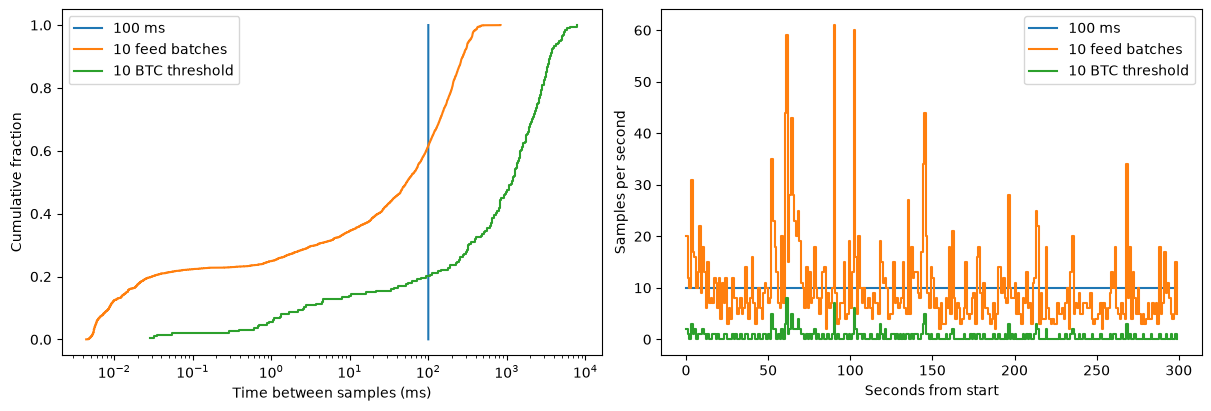

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, records in samples.items():
    duration_ms = np.diff(np.concatenate(([start], records['timestamp']))) / 1e6
    duration_ms = np.sort(duration_ms)
    axes[0].step(duration_ms, np.arange(1, len(records) + 1) / len(records),
                 where='post', label=name)
axes[0].set(xscale='log', xlabel='Time between samples (ms)', ylabel='Cumulative fraction')
axes[0].legend()

edges = np.arange(start, end + second, second, dtype=np.int64)
for name, records in samples.items():
    counts = np.diff(np.searchsorted(records['timestamp'], edges, side='right'))
    axes[1].step((edges[:-1] - start) / second, counts, where='post', label=name)
axes[1].set(xlabel='Seconds from start', ylabel='Samples per second')
axes[1].legend()
plt.show()

The fixed clock has constant elapsed spacing but variable feed activity per observation.
The event clock has constant feed-batch counts but variable elapsed spacing. The volume
clock varies both, and its realized volume can exceed 10 BTC because batches are kept
intact. The plots describe this particular feed and short period; they do not establish
independent observations, stationary returns or improved predictive performance.

All three clocks replay the underlying feed. Sampling less often does not skip the
engine's order-book reconstruction work. Here the shared loop deliberately visits every
feed batch to make the counts and volume directly comparable.

## Using the observations for research

Features are available at the recorded local timestamp. If adding forward-return labels,
choose a common physical horizon, for example `m(t + 1 second) / m(t) - 1`, with the mid
at the horizon taken from the latest available book at or before that time. Use a common
feed-state history or another replay for the targets and discard incomplete tails.
Shifting each sampled table by one row gives different elapsed horizons across clocks.

Keep future labels separate from contemporaneous features. Fit thresholds and any
normalization on an earlier training period, and account for overlapping label horizons
when splitting data. This notebook intentionally stops at sampling and diagnostics.

## A small boundary example

Two trades received at the same timestamp count as one batch. Quiet 100 ms boundaries
must still be emitted. A depth-only update counts toward the event clock but not traded
volume, and a trade at a grid boundary belongs to the interval ending there. The
synthetic stream below makes those distinctions explicit, including volume overshoot.

In [7]:
from hftbacktest import event_dtype, EXCH_EVENT, BUY_EVENT, SELL_EVENT, DEPTH_EVENT

base = 1_700_000_000_000_000_001  # Deliberately not representable as float64 ns.
flags = EXCH_EVENT | LOCAL_EVENT
fixture = np.array([
    (flags | BUY_EVENT | DEPTH_EVENT, base, base, 100, 4, 0, 0, 0),
    (flags | SELL_EVENT | DEPTH_EVENT, base, base, 101, 6, 0, 0, 0),
    *[(flags | BUY_EVENT | TRADE_EVENT, base + t, base + t, 101, qty, 0, 0, 0)
      for t, qty in [(20_000_000, 1), (20_000_000, 3), (250_000_000, 3)]],
    (flags | BUY_EVENT | DEPTH_EVENT, base + 400_000_000, base + 400_000_000,
     100, 10, 0, 0, 0),
    (flags | BUY_EVENT | TRADE_EVENT, base + 500_000_000, base + 500_000_000,
     101, 6, 0, 0, 0),
    (flags | BUY_EVENT | DEPTH_EVENT, base + 600_000_000, base + 600_000_000,
     100, 10, 0, 0, 0),
], dtype=event_dtype)

test_asset = (BacktestAsset().data(fixture).tick_size(1).lot_size(1)
              .last_trades_capacity(10))
hbt = HashMapMarketDepthBacktest([test_asset])
try:
    fixed, event, volume = sample_clocks(
        hbt, base, base + 500_000_000, 100_000_000, 2, 5.0, 10
    )
finally:
    hbt.close()

np.testing.assert_array_equal(fixed['timestamp'] - base, np.arange(1, 6) * 100_000_000)
np.testing.assert_array_equal(fixed['feed_batches'], [1, 0, 1, 1, 1])
np.testing.assert_allclose(fixed['trade_qty'], [4, 0, 3, 0, 6])
np.testing.assert_allclose(fixed['mid_price'], 100.5)
np.testing.assert_allclose(fixed['spread_ticks'], 1)
np.testing.assert_allclose(fixed['imbalance'], [-0.2, -0.2, -0.2, 0.25, 0.25])
for records in (event, volume):
    np.testing.assert_array_equal(records['timestamp'] - base, [250_000_000, 500_000_000])
    np.testing.assert_array_equal(records['feed_batches'], [2, 2])
    np.testing.assert_allclose(records['trade_qty'], [7, 6])
print('Same-timestamp batches, timeouts, grid ties and volume overshoot verified.')

Same-timestamp batches, timeouts, grid ties and volume overshoot verified.
